# Data Leakage and Reproducibility

This notebook demonstrates how preprocessing fitted before the split inflates scores, how leakage can fabricate accuracy on pure noise, and how to keep experiments honest and reproducible.

## Import Required Libraries

Import the datasets, preprocessing, model and validation tools.

In [1]:
# Import the required libraries.
import sys
import numpy as np
import matplotlib.pyplot as plt

import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)
from sklearn.metrics import accuracy_score

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## The Wrong Way: Preprocess Before Splitting

Fitting the scaler and feature selector on the whole dataset lets test information leak into training, inflating the score.

In [2]:
# Leak information by preprocessing the full dataset first.
data = load_breast_cancer()
X, y = data.data, data.target

# Fit scaling and selection on ALL data (leakage).
X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_classif, k=10).fit_transform(X_scaled, y)

# Only now split into train and test.
X_tr, X_te, y_tr, y_te = train_test_split(
    X_sel, y, test_size=0.3, random_state=42, stratify=y
)
leaky = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
leaky_score = accuracy_score(y_te, leaky.predict(X_te))
print(f"Leaky holdout accuracy: {leaky_score:.4f}.")

Leaky holdout accuracy: 0.9357.


## The Right Way: Pipeline Inside Cross-Validation

Wrapping preprocessing in a `Pipeline` refits it on each training fold only, producing an honest estimate.

In [3]:
# Keep preprocessing inside the CV loop with a pipeline.
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(f_classif, k=10)),
    ("clf", LogisticRegression(max_iter=5000)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
honest = cross_val_score(pipe, X, y, cv=cv)
print(f"Honest CV accuracy: {honest.mean():.4f} "
      f"(+/- {honest.std():.4f}).")
print(f"Difference vs leaky: "
      f"{leaky_score - honest.mean():+.4f}.")

Honest CV accuracy: 0.9508 (+/- 0.0162).
Difference vs leaky: -0.0151.


## Leakage on Pure Noise

With many random features, selecting the best ones on the whole dataset before cross-validation can fabricate accuracy well above the 50 percent chance level.

In [4]:
# Build a dataset of pure noise features and random labels.
n_samples, n_features = 200, 10000
X_noise = np.random.randn(n_samples, n_features)
y_noise = np.random.randint(0, 2, size=n_samples)

# WRONG: select features on all data before CV.
X_leak = SelectKBest(f_classif, k=20).fit_transform(
    X_noise, y_noise
)
leak_noise = cross_val_score(
    LogisticRegression(max_iter=5000), X_leak, y_noise, cv=5
).mean()
print(f"Leaky noise accuracy: {leak_noise:.4f} (should ~0.5).")

Leaky noise accuracy: 0.8600 (should ~0.5).


## The Honest Estimate on Noise

Selecting features inside the pipeline collapses the accuracy back to the chance level, exposing the earlier score as fake.

In [5]:
# CORRECT: select features inside the CV pipeline.
noise_pipe = Pipeline([
    ("select", SelectKBest(f_classif, k=20)),
    ("clf", LogisticRegression(max_iter=5000)),
])
honest_noise = cross_val_score(
    noise_pipe, X_noise, y_noise, cv=5
).mean()
print(f"Honest noise accuracy: {honest_noise:.4f}.")

Honest noise accuracy: 0.4150.


## Visualise the Inflation

Compare leaky and honest estimates for both the real dataset and the noise dataset.

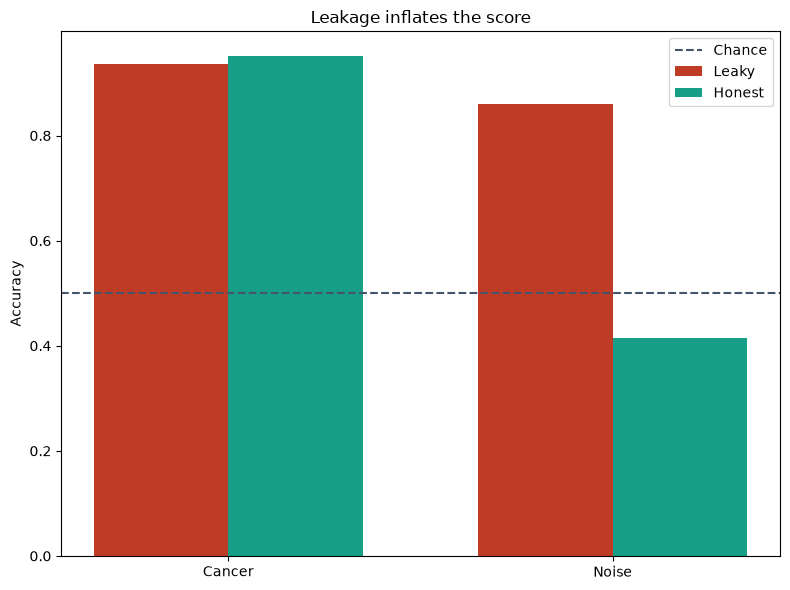

In [6]:
# Plot leaky vs honest accuracy for both datasets.
fig, ax = plt.subplots(figsize=(8, 6))
labels = ["Cancer", "Noise"]
leaky_vals = [leaky_score, leak_noise]
honest_vals = [honest.mean(), honest_noise]
x_pos = np.arange(len(labels))
width = 0.35
ax.bar(x_pos - width / 2, leaky_vals, width, color=colors[3],
       label="Leaky")
ax.bar(x_pos + width / 2, honest_vals, width, color=colors[0],
       label="Honest")
ax.axhline(0.5, color=colors[4], linestyle="--",
           label="Chance")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels)
ax.set_ylabel("Accuracy")
ax.set_title("Leakage inflates the score")
ax.legend()
plt.tight_layout()
plt.show()

## Reproducibility: Seeds and Versions

Fixing seeds and recording library versions lets others reproduce the exact numbers.

In [7]:
# Print seeds and library versions for reproducibility.
np.random.seed(42)
print(f"Python:       {sys.version.split()[0]}.")
print(f"NumPy:        {np.__version__}.")
print(f"scikit-learn: {sklearn.__version__}.")
print("Global seed:  42.")

Python:       3.12.13.
NumPy:        2.5.2.
scikit-learn: 1.9.0.
Global seed:  42.


## Reproducibility Checklist

A short checklist to keep evaluations trustworthy and repeatable.

- **Fix all seeds**: set `random_state` on splitters, models and generators, and seed NumPy.
- **Split first**: fit every transformer on training data only, ideally inside a `Pipeline`.
- **Record versions**: log Python and library versions with the results.
- **Automate**: rerun the whole notebook top to bottom to confirm the numbers are stable.

## Summary

- **Data leakage**: fitting preprocessing before the split leaks test information and inflates the reported score.
- **Pipelines**: refit preprocessing per fold, giving an honest cross-validation estimate.
- **Noise trap**: selecting features on all data can fabricate accuracy on data with no real signal.
- **Reproducibility**: fixed seeds, split-first discipline and recorded versions make results repeatable.